# Bits and basis states

A classical computer stores everything as bits, and a program is a sequence of
operations that set, clear, and combine them. Before any quantum idea appears,
this notebook rewrites those familiar things in the language of linear
algebra: a bit becomes a vector, and an operation on a bit becomes a matrix.

Two questions drive the notebook. How do we write "bit 2 is 1 and bits 1 and 0
are 0" as a vector, and "set this bit to 1" as a matrix? And how do we hand a
small program like that to a real quantum computer, `ibm_rensselaer`, and read
the answer back?

## Before you start

This notebook assumes only the course prerequisites listed in the
[unit README](../README.md#before-you-start): matrix-vector products, binary
numbers, and Python with NumPy.

Quick check:

1. What is $\begin{pmatrix}0&1\\0&0\end{pmatrix}\begin{pmatrix}0\\1\end{pmatrix}$?
2. What is the binary number $101$ in decimal?
3. In NumPy, what does `np.array([[0, 1], [0, 0]]) @ np.array([1, 0])` return?

Answers: $\begin{pmatrix}1\\0\end{pmatrix}$; $5$; `array([0, 0])`.

After this notebook you will be able to:

1. Write any string of up to four bits as a column vector, and read the bits
   back from such a vector.
2. Compute, with a matrix, the effect of setting a bit to 1 or clearing it
   to 0.
3. Write a short Qiskit program that prepares a chosen string of bits on a
   quantum computer and reads it back.

## Setup

This cell loads the libraries and decides where circuits run. By default it
uses only the simulator on your computer; the exercises at the end show how to
add `ibm_rensselaer`.

`SETTINGS` is a `SimpleNamespace`, a plain Python object that holds named
values such as `SETTINGS.shots`. The section "Circuits and measurement" below
explains `shots`. Three settings matter only for hardware: `backend` (which
IBM machine), `name` (your saved IBM account) and `poll_interval` (how often
to check a waiting job). `precision` is used from Notebook 09 on.
`get_targets` returns the list `targets` of places to run; the section "From
circuit to counts" describes what a target holds.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# the Aer simulator, plus IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## One bit as a vector

A bit has two values, 0 and 1. Linear algebra works with vectors, so we need a
vector for each value. The simplest choice that keeps the two values distinct
is a two-component column vector with a single 1 in it: the 1 sits in the
first slot for the value 0 and in the second slot for the value 1.

These two vectors are the *basis states* of one bit:

$$|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}.$$

In words: the basis state for a value is the column vector with a 1 in the
slot numbered by that value (counting slots from 0) and 0 everywhere else.

The bracket $|\;\rangle$ is a *ket*. A ket is a column vector, and the label
inside it names the vector. So $|1\rangle$ is read "ket one" and is the vector
$(0, 1)^T$.

A *qubit* is the device in a quantum computer that stores the state of one
bit. In Notebooks 00 to 03 a qubit only ever holds $|0\rangle$ or $|1\rangle$,
so for now a qubit is a bit with a vector attached. A *register* is a group of
bits or qubits numbered 0, 1, 2, and so on.

Writing a bit as a vector looks like extra work for no gain. It pays off in
the next section, where every operation on bits becomes a matrix, and in
Notebook 04, where the slots of the vector are allowed to hold numbers other
than 0 and 1.

**Check.** Which basis state is the vector $(0, 1)^T$, and which value of the
bit does it stand for?

## Several bits: the tensor product

Two bits have four combined values, 00, 01, 10 and 11. Following the same rule
as for one bit, give each combined value a four-component vector with a single
1 in it. The slot that holds the 1 is the binary number the two bits spell:
$00 \to$ slot 0, $01 \to$ slot 1, $10 \to$ slot 2, $11 \to$ slot 3.

A *bitstring* is the combined value of a register, written with **bit 0 on
the right**: $|x_1 x_0\rangle$ means bit 1 has value $x_1$ and bit 0 has value
$x_0$. This is the order Qiskit uses when it prints results. Many textbooks
use the opposite order, so this course states it every time it matters.

The vector of a bitstring can be built from the vectors of its bits with the
*tensor product* (also called the Kronecker product). For two column vectors
$u = (u_0, u_1)^T$ and $v$, the tensor product stacks a copy of $v$ scaled by
each entry of $u$:

$$u \otimes v = \begin{pmatrix} u_0\, v \\ u_1\, v \end{pmatrix}.$$

In words: replace each entry of the left vector by that entry times the whole
right vector. The result has as many entries as the product of the two
lengths. Then

$$|x_1 x_0\rangle = |x_1\rangle \otimes |x_0\rangle,$$

with the leftmost bit as the leftmost factor, and the same pattern continues
for more bits: $|x_2 x_1 x_0\rangle = |x_2\rangle \otimes |x_1\rangle \otimes |x_0\rangle$.

With three factors there are two ways to group them, $(u \otimes v) \otimes w$
and $u \otimes (v \otimes w)$, and both give the same vector. For two-entry
vectors, each grouping puts the product $u_i v_j w_k$ in slot $4i + 2j + k$.
So the tensor product is *associative*: the grouping does not matter, and the
parentheses can be dropped. Example 1 groups from the right; the code after
it also groups from the left and gets the same vector.

### Example 1: the vector for $|101\rangle$

**Problem.** Write the three-bit bitstring $|101\rangle$ as a column vector.

**Plan.** Build it from the right with two tensor products, then check that
the 1 lands in the slot numbered by the binary number $101$.

**Solution.**

**Subgoal 1: combine bits 1 and 0.**

1. The two rightmost characters are $x_1 = 0$ and $x_0 = 1$, so we need
   $|0\rangle \otimes |1\rangle$.
2. Apply the definition with $u = |0\rangle = (1, 0)^T$: the top block is
   $1 \cdot (0, 1)^T$ and the bottom block is $0 \cdot (0, 1)^T$.
3. Stack the blocks: $|01\rangle = (0, 1, 0, 0)^T$.

**Subgoal 2: add bit 2.**

4. Bit 2 is $x_2 = 1$, so we need $|1\rangle \otimes (0, 1, 0, 0)^T$ with
   $u = |1\rangle = (0, 1)^T$.
5. The top block is $0 \cdot (0, 1, 0, 0)^T$, four zeros. The bottom block is
   $1 \cdot (0, 1, 0, 0)^T$.
6. Stack the blocks: $|101\rangle = (0, 0, 0, 0, 0, 1, 0, 0)^T$.

**Check.** The binary number $101$ is $1\cdot 4 + 0 \cdot 2 + 1 \cdot 1 = 5$,
and the only 1 in the vector is in slot 5 (counting from 0). The vector also
has $2^3 = 8$ entries, one for each three-bit value.

**Self-explanation prompt.** Why does the tensor product always put the 1 in
the slot numbered by the binary value? **Answer.** Each extra bit on the left
doubles the length. If the new bit is 0 the old vector lands in the top half,
and if it is 1 the old vector lands in the bottom half, which adds $2^k$ to
the slot number for bit $k$. That is exactly how a binary number adds up.

**Takeaway.** An $n$-bit bitstring is a vector with $2^n$ entries and a single
1, in the slot whose number is the bitstring read as a binary number.

In [2]:
ket0 = np.array([1, 0])
ket1 = np.array([0, 1])

ket_01 = np.kron(ket0, ket1)          # bits 1 and 0
ket_101 = np.kron(ket1, ket_01)       # add bit 2 on the left
print("|01>  =", ket_01)
print("|101> =", ket_101)
print("slot holding the 1:", int(np.argmax(ket_101)), "  binary 101 =", int("101", 2))

# The other grouping: bits 2 and 1 first, then bit 0 on the right.
left_first = np.kron(np.kron(ket1, ket0), ket1)
same = np.array_equal(left_first, ket_101)
print("grouped from the left gives the same vector:", same)

|01>  = [0 1 0 0]
|101> = [0 0 0 0 0 1 0 0]
slot holding the 1: 5   binary 101 = 5
grouped from the left gives the same vector: True


A common mistake is to read the bitstring from left to right as bit 0, bit 1,
bit 2. That is wrong in this course and in Qiskit: in $|101\rangle$ the
rightmost character is bit 0. The mistake is tempting because we read text
from the left, and because some books number the bits that way. When the two
outer bits are equal, as in $101$, the order makes no difference, which is
why the experiment below also uses bitstrings that are not palindromes.

**Check.** Which bitstring is the eight-component vector whose 1 is in slot 6?

## Setting and clearing a bit: $a^\dagger$ and $a$

A program changes bits. The two most basic changes to one bit are to *set* it
(change 0 to 1) and to *clear* it (change 1 to 0). Since a bit is now a
vector, each change should be a $2\times2$ matrix.

Start with setting. We want a matrix that sends $|0\rangle$ to $|1\rangle$.
What should it do to a bit that is already 1? The convention used throughout
this course is that setting a bit that is already set is not allowed, and the
matrix signals this by returning the zero vector $(0, 0)^T$, written $0$. The
zero vector is not a basis state and does not describe any bit; it is the
matrix's way of saying "this operation cannot act on this input".

The *creation operator* $a^\dagger$ sets a bit, and the *annihilation
operator* $a$ clears it:

$$a^\dagger = \begin{pmatrix}0&0\\1&0\end{pmatrix}, \qquad a = \begin{pmatrix}0&1\\0&0\end{pmatrix}.$$

They act as

$$a^\dagger|0\rangle = |1\rangle,\quad a^\dagger|1\rangle = 0, \qquad a|1\rangle = |0\rangle,\quad a|0\rangle = 0.$$

In words: $a^\dagger$ turns a 0 into a 1 and refuses a 1; $a$ turns a 1 into
a 0 and refuses a 0. The matrix $a^\dagger$ is the transpose of $a$.

The names come from physics, where a bit value of 1 often means "a particle
is present here": creating a particle sets the bit, and annihilating it clears
the bit. You will meet that reading again in Units 3 and 4. The symbol
$a^\dagger$ is read "a-dagger"; Notebook 04 explains what the dagger means in
general.

### Example 2: what $a^\dagger$ and $a$ do, one after the other

**Problem.** Compute $a^\dagger|0\rangle$, then clear the result with $a$.
Then compute $a\,a^\dagger|1\rangle$.

**Plan.** Multiply matrices and vectors one at a time, right to left, because
the operator written closest to the ket acts first.

**Solution.**

**Subgoal 1: set a bit that is 0, then clear it.**

1. Multiply $a^\dagger$ by $|0\rangle = (1, 0)^T$: the first row gives
   $0\cdot1 + 0\cdot0 = 0$ and the second row gives $1\cdot1 + 0\cdot0 = 1$.
   So $a^\dagger|0\rangle = (0, 1)^T = |1\rangle$.
2. Multiply $a$ by that result, $|1\rangle = (0, 1)^T$: the first row gives
   $0\cdot0 + 1\cdot1 = 1$ and the second row gives $0$. So
   $a\,a^\dagger|0\rangle = |0\rangle$.

**Subgoal 2: try the same pair on a bit that is 1.**

3. Multiply $a^\dagger$ by $|1\rangle = (0, 1)^T$: both rows give 0, so
   $a^\dagger|1\rangle = 0$.
4. Any matrix times the zero vector is the zero vector, so
   $a\,a^\dagger|1\rangle = a\,0 = 0$.

**Check.** The columns of a matrix are what it does to $(1, 0)^T$ and
$(0, 1)^T$. The columns of $a^\dagger$ are $(0, 1)^T$ and $(0, 0)^T$, which
matches steps 1 and 3.

**Takeaway.** "Set, then clear" returns a bit that was 0 to 0, but gives the
zero vector for a bit that was 1, because the first step already failed. The
order of the operators and the input both matter.

In [3]:
a = np.array([[0, 1], [0, 0]])
a_dag = a.T                            # a-dagger is the transpose of a

print("a_dag @ |0> =", a_dag @ ket0)
print("a_dag @ |1> =", a_dag @ ket1)
print("a     @ |1> =", a @ ket1)
print("a     @ |0> =", a @ ket0)
print("a @ a_dag @ |0> =", a @ a_dag @ ket0)
print("a @ a_dag @ |1> =", a @ a_dag @ ket1)

a_dag @ |0> = [0 1]
a_dag @ |1> = [0 0]
a     @ |1> = [1 0]
a     @ |0> = [0 0]
a @ a_dag @ |0> = [1 0]
a @ a_dag @ |1> = [0 0]


A common mistake is to think that $a$ undoes $a^\dagger$, so that applying
both leaves every bit unchanged. Example 2 shows this is wrong: $a\,a^\dagger$
leaves $|0\rangle$ unchanged but sends $|1\rangle$ to $0$. The idea is
tempting because "clear" sounds like the opposite of "set", and it is the
opposite on the one input where "set" succeeds. Notebook 01 turns this
observation into the first useful operators.

On a quantum computer the basic hardware operation on one qubit is NOT, which
flips the bit whatever its value. On a qubit that holds $|0\rangle$, NOT does
exactly what $a^\dagger$ does. Every qubit starts in $|0\rangle$, so the
experiment below uses NOT to set bits. Notebook 01 builds NOT out of $a$ and
$a^\dagger$.

**Check.** What is $a^\dagger a^\dagger|0\rangle$, and what does it say about
setting a bit twice?

## Circuits and measurement

A quantum program is called a circuit. A *circuit* is a list of operations
applied to a register in order. Qiskit draws it as one horizontal line per
qubit, qubit 0 at the top, with time running from left to right. Each
operation in a circuit is a *gate*. In Qiskit, every qubit of a new
`QuantumCircuit` starts in $|0\rangle$, and `circuit.x(k)` applies NOT to
qubit $k$. The qubit can be named by its number, as in `circuit.x(2)`, or by
its entry in a register, as in `circuit.x(qubits[2])`; both mean the same
qubit.

A *measurement* reads a qubit and writes the result, 0 or 1, into an ordinary
(classical) bit that the program can see. For the states in Notebooks 00 to
03, which are always bitstrings, the measurement returns that bitstring
exactly. Each qubit in a circuit is measured into its own classical bit.

One run of a circuit from the start to the measurement is a *shot*. A program
usually asks for thousands of shots, and the result is a table of *counts*:
how many shots gave each bitstring. If every result is predictable, why repeat
the run? Two reasons. Real hardware makes errors, and the counts show how
often. And from Notebook 04 on, the result of a single shot is random, so only
the counts carry the answer.

One hardware error appears in almost every experiment. The qubits of
`ibm_rensselaer` are small superconducting circuits, cooled close to absolute
zero. A qubit holding 1 can relax to 0 before its measurement finishes, while
a qubit holding 0 rarely turns into 1. So a 1 is misread as 0 more often than
a 0 is misread as 1, and wrong readings lean toward 0. A wrong reading of
this kind is a *readout error*.

How large a difference from the expected counts is a real effect? Suppose a
fraction $p$ of $N$ shots gives some outcome. Repeating the whole run would
give a slightly different fraction, and the typical size of that random
*scatter* is about $\sqrt{p(1-p)/N}$. This formula is stated here without
proof; Notebook 09 derives it. The *scatter rule* used throughout the course
has three parts:

- most runs (about 19 in 20) land within twice the scatter of the ideal
  value;
- a difference of two to three times the scatter happens by chance now and
  then;
- a difference of more than three times the scatter is a real effect, not
  chance.

For example, with $N = 4096$ shots and $p = 0.5$ the scatter is
$\sqrt{0.25/4096} \approx 0.008$. Most runs then give a fraction between
about 0.484 and 0.516, and a fraction below 0.476 or above 0.524 signals a
real effect.

**Check.** A circuit on three qubits applies NOT to qubit 0 and qubit 2 and
then measures. Which bitstring should every shot return?

## From circuit to counts

Running a circuit takes a few more pieces. They appear in every notebook of
the course, so they are defined once here.

- A *backend* is anything that runs circuits. This course uses two: the Aer
  *simulator*, a program on your computer that calculates what an error-free
  quantum computer would return, and `ibm_rensselaer`, the IBM quantum
  computer on the RPI campus.
- Each backend has its own set of native gates and its own wiring between
  qubits. To *transpile* a circuit is to rewrite it using only the gates and
  connections of one backend. The result is an *ISA circuit* (ISA stands for
  instruction set architecture, the set of operations a machine can run).
- A *primitive* is the Qiskit object that runs ISA circuits on a backend and
  returns results. This unit uses two. The *Sampler* runs circuits that end in
  measurements and returns counts. The other, the Estimator, appears in
  Notebook 09.
- A *PUB* (primitive unified bloc) is a Python tuple that tells a primitive
  what to run. Its first element is an ISA circuit; later notebooks add more
  elements. A single submission can contain many PUBs.
- A *job* is one submission of PUBs to a primitive. On the simulator it
  finishes at once; on hardware it waits in a queue first.
- In code, the Setup cell's `get_targets` returns a list of *targets*, one
  per backend in use. Each target bundles a `label` (`"aer"` or the IBM
  backend's name), the `backend`, a `sampler`, an `estimator` (used from
  Notebook 09 on), and a method `wait(job)` that returns a job's result,
  waiting in the hardware queue if needed.

These pieces fill the Execution step of the recipe used in every notebook:
**Encoding** (how the problem is stored in qubits), **Operator** (what is
applied and measured), **Execution** (transpile, build PUBs, run the job), and
**Analysis** (turn counts into an answer and compare with theory). The
[unit README](../README.md#the-recipe) has the full table.

## The experiment: prepare three bitstrings and read them back

We prepare three bitstrings, $|101\rangle$, $|011\rangle$ and $|110\rangle$,
and check that the Sampler returns each one. The last two are not
palindromes, so getting them back confirms the bit order.

### Encoding

A bitstring is stored by putting each qubit in the basis state of its bit.
Qubit $k$ needs a NOT when bit $k$ is 1. Because bit 0 is the rightmost
character, bit $k$ is character `bitstring[-1 - k]` in Python.

The function below uses three Qiskit pieces. `QuantumRegister(n, name="q")`
is a register of $n$ qubits, and `ClassicalRegister(n, name="meas")` is a
register of $n$ classical bits that will hold the measured results.
`QuantumCircuit(qubits, bits)` builds an empty circuit on both, and
`circuit.measure(qubits, bits)` measures qubit $k$ into classical bit $k$ for
every $k$. Finally, `draw("mpl")` draws a circuit as a picture (`"mpl"` stands
for Matplotlib, the plotting library that draws it).

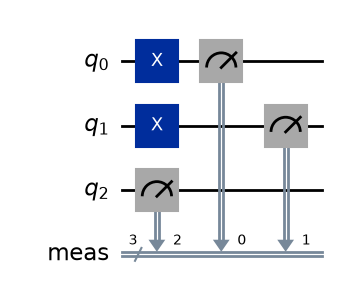

In [4]:
def prepare(bitstring):
    """Return a circuit that prepares |bitstring> and measures every qubit."""
    num_bits = len(bitstring)
    qubits = QuantumRegister(num_bits, name="q")
    bits = ClassicalRegister(num_bits, name="meas")
    circuit = QuantumCircuit(qubits, bits, name=bitstring)
    for k in range(num_bits):
        if bitstring[-1 - k] == "1":
            circuit.x(qubits[k])
    circuit.measure(qubits, bits)
    return circuit


bitstrings = ["101", "011", "110"]
circuits = {b: prepare(b) for b in bitstrings}
circuits["011"].draw("mpl")

In the drawing, qubit 0 ($q_0$) is the top line. For $|011\rangle$, bits 0
and 1 are 1, so the NOT gates sit on the top two lines. Qiskit labels NOT
with the letter X; Notebook 01 explains the name.

The exact answer comes from Example 1: each bitstring is the vector with a 1
in the slot of its binary value.

In [5]:
for b in bitstrings:
    vector = np.array([1])
    for character in b:                # leftmost character is the leftmost factor
        vector = np.kron(vector, ket1 if character == "1" else ket0)
    print(f"|{b}> -> 1 in slot {int(np.argmax(vector))}  (binary {b} = {int(b, 2)})")

|101> -> 1 in slot 5  (binary 101 = 5)
|011> -> 1 in slot 3  (binary 011 = 3)
|110> -> 1 in slot 6  (binary 110 = 6)


### Operator

In this notebook nothing is applied after the preparation: the operator is
"do nothing, then measure every qubit". Notebook 01 puts the first real
operators here.

### Execution

Transpiling is done by a *pass manager*: a sequence of rewriting steps
("passes") prepared for one backend. `generate_preset_pass_manager` builds one
from a backend and an `optimization_level` from 0 to 3. Level 0 only rewrites
into native gates; level 1, used in this course, also makes light
simplifications, such as deleting two gates in a row that undo each other.
For the simulator the circuits barely change; for hardware they are rewritten
into native gates and placed on physical qubits.

Each PUB holds one ISA circuit. `target.sampler.run(list_of_pubs,
shots=N)` submits one job that runs each PUB's circuit $N$ times and returns
the job, and `target.wait(job)` returns its result. Here one job carries all
three PUBs.

In [6]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {b: pass_manager.run(c) for b, c in circuits.items()}

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # wait() returns None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

### Analysis

`results[label]` is the result of the job on one backend, and its entry `i`
belongs to the PUB `pubs[label][i]`. Each entry's `.data.meas` field holds the
shots recorded in the classical register we named `meas`, and `get_counts()` turns
them into a dictionary from bitstring to count. The fraction of shots on the
prepared bitstring should be 1.000 on the simulator.

In [7]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots:")
    for b, pub_result in zip(bitstrings, result):
        counts = pub_result.data.meas.get_counts()
        on_target = counts.get(b, 0) / SETTINGS.shots
        print(f"  prepared {b}: counts {counts}   fraction on {b} = {on_target:.3f}")

aer, 4096 shots:
  prepared 101: counts {'101': 4096}   fraction on 101 = 1.000
  prepared 011: counts {'011': 4096}   fraction on 011 = 1.000
  prepared 110: counts {'110': 4096}   fraction on 110 = 1.000


Every shot returned the bitstring that was prepared, and the keys of the
counts follow the same order as the kets: bit 0 on the right.

## Exercises

1. Write $|011\rangle$ as an eight-component vector by hand, using two tensor
   products. Check your answer with `np.kron`.
2. Which four-bit bitstring is the sixteen-component vector whose 1 is in
   slot 9?
3. Compute $a^\dagger a^\dagger$ and $a\,a$ as matrices. What do the results
   say about setting a bit twice and clearing it twice?
4. Write a function `prepare_integer(m)` that returns the circuit preparing
   the three-bit binary form of an integer $0 \le m \le 7$. Before you run it
   for $m = 6$, predict the counts key.
5. True or false: in Qiskit's counts, the key `"01"` means qubit 0 measured 0
   and qubit 1 measured 1. Give the reason.
6. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook again. What fraction of shots lands on each prepared bitstring on
   `ibm_rensselaer`? Using the scatter rule from "Circuits and measurement",
   is the gap between the hardware fraction and 1.000 chance or a real
   effect?
7. (hardware) Change `bitstrings` to `["000", "111"]` and run on hardware
   again. Which one has more wrong shots, and does that fit the hardware error
   described in "Circuits and measurement"? Among the wrong shots, do most
   differ from the target in one bit or in several?

## What you can now do

1. Write a string of up to four bits as a column vector with the tensor
   product, and read the bits back from the slot that holds the 1.
2. Compute the effect of $a^\dagger$ (set) and $a$ (clear) on a bit, including
   the zero vector when the operation is not allowed.
3. Prepare a chosen bitstring with a Qiskit circuit, run it through the
   Encoding, Operator, Execution and Analysis steps, and read the counts.

## Solutions

**Check, one bit as a vector.** $(0, 1)^T$ is $|1\rangle$, the bit with
value 1.

**Check, tensor product.** Slot 6 is binary $110$, so the bitstring is
$|110\rangle$: bit 2 and bit 1 are 1, bit 0 is 0.

**Check, setting and clearing.** $a^\dagger|0\rangle = |1\rangle$, and then
$a^\dagger|1\rangle = 0$. Setting a bit twice is not allowed, and the zero
vector records that.

**Check, circuits.** NOT on qubits 0 and 2 sets bits 0 and 2, so every shot
returns $101$.

**Exercise 1.** Bits 1 and 0 are both 1, so first
$|1\rangle \otimes |1\rangle$: the top block is $0\cdot(0,1)^T$ and the bottom
block is $1\cdot(0,1)^T$, giving $(0, 0, 0, 1)^T$. Then
$|0\rangle \otimes (0,0,0,1)^T$ puts that vector in the top half:
$|011\rangle = (0, 0, 0, 1, 0, 0, 0, 0)^T$. **Check.** Binary $011 = 3$, and
the 1 is in slot 3. In code, `np.kron(ket0, np.kron(ket1, ket1))`.

**Exercise 2.** Write 9 in binary with four bits: $9 = 8 + 1 = 1001_2$. The
bitstring is $|1001\rangle$, with bits 3 and 0 equal to 1.

**Exercise 3.** Multiply the matrices:
$a^\dagger a^\dagger = \begin{pmatrix}0&0\\1&0\end{pmatrix}\begin{pmatrix}0&0\\1&0\end{pmatrix} = \begin{pmatrix}0&0\\0&0\end{pmatrix}$,
and in the same way $a\,a = 0$. Both are the zero matrix, which sends every
input to the zero vector. Setting a bit twice fails on every input, because
after the first step the bit is 1 (or the first step already failed); the
same holds for clearing twice.

**Exercise 4.** The three-bit form of $m$ is `format(m, "03b")`, so the
function can reuse `prepare` from the Encoding step:

```python
def prepare_integer(m):
    return prepare(format(m, "03b"))
```

For $m = 6$ the bitstring is $110$: NOT gates on qubits 1 and 2, and every
shot returns the key `"110"`.

**Exercise 5.** False. Qiskit prints qubit 0 as the rightmost character, so
`"01"` means qubit 0 measured 1 and qubit 1 measured 0.

**Exercise 6.** Expect a fraction a little below 1.000 (the exact value
depends on the day's calibration), with the missing shots spread over other
bitstrings. With $N = 4096$ and $p$ near 0.98, the scatter is about
$\sqrt{0.98 \times 0.02 / 4096} \approx 0.002$, and three times that is
0.007. A gap of a percent or more is beyond three times the scatter, so by the
scatter rule it is a real hardware error, not chance.

**Exercise 7.** Expect more wrong shots for $111$ than for $000$. As
"Circuits and measurement" describes, a qubit that holds 1 can relax to 0
before its measurement finishes, while a 0 rarely becomes a 1, so wrong shots
for $111$ are mostly bitstrings with one 1 changed to 0. Errors
in different qubits are mostly independent and each is rare, so wrong shots
that differ in two or more bits are much less common than single-bit errors.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| basis state | the vector of one value of a bit: $\lvert 0\rangle = (1,0)^T$, $\lvert 1\rangle = (0,1)^T$ |
| ket | the notation $\lvert\;\rangle$ for a column vector, labeled by what is inside |
| qubit | the device that stores one bit's state; in Notebooks 00 to 03 it holds only $\lvert 0\rangle$ or $\lvert 1\rangle$ |
| register | a group of bits or qubits numbered 0, 1, 2, ... |
| bitstring | the combined value of a register, written with bit 0 on the right |
| tensor product | $u \otimes v$: each entry of $u$ replaced by that entry times all of $v$ |
| associative | the grouping of several tensor products does not change the result |
| creation operator $a^\dagger$ | sets a bit: $a^\dagger\lvert 0\rangle = \lvert 1\rangle$, $a^\dagger\lvert 1\rangle = 0$ |
| annihilation operator $a$ | clears a bit: $a\lvert 1\rangle = \lvert 0\rangle$, $a\lvert 0\rangle = 0$ |
| circuit | a list of operations applied to a register in order |
| gate | one operation in a circuit |
| measurement | reads a qubit into a classical bit, 0 or 1 |
| shot | one run of a circuit through its measurement |
| counts | how many shots returned each bitstring |
| readout error | a wrong measured bit on hardware; a 1 is misread as 0 more often than a 0 as 1 |
| scatter | the typical random variation of a fraction $p$ from $N$ shots, about $\sqrt{p(1-p)/N}$ |
| scatter rule | within twice the scatter: most runs (about 19 in 20); two to three times: chance now and then; more than three times: a real effect |
| backend | anything that runs circuits: the Aer simulator or `ibm_rensselaer` |
| simulator | a program that calculates what an error-free quantum computer would return |
| transpile | rewrite a circuit using only one backend's gates and connections |
| ISA circuit | the transpiled circuit (instruction set architecture) |
| pass manager | the sequence of transpiling steps prepared for one backend |
| target | in code, one backend in use, bundled with its Sampler, Estimator and `wait` method |
| primitive | the Qiskit object that runs ISA circuits and returns results |
| Sampler | the primitive that returns counts of measured bitstrings |
| PUB | primitive unified bloc: a tuple whose first element is the ISA circuit to run |
| job | one submission of PUBs to a primitive |